```markdown
# Hyperparameter Tuning for Neural Network Classification

This notebook outlines the process of optimizing a deep learning classifier step-by-step using Keras Tuner.

The search is structured as follows:
1. **First Model (Basic Baseline)**: Building a simple feedforward neural network baseline.
2. **Second Model (Tuning #Neurons)**: Finding the optimal number of hidden units in our layer.
3. **Third Model (Tuning #Layers)**: Optimizing depth by searching for the best number of layers.
4. **Fourth Model (Complete Search space along with Dropout)**: A comprehensive search space tuning width, depth, activation functions, optimizers, and including dropout for regularization.
```

In [29]:
import numpy as np
import pandas as pd

In [30]:
df = pd.read_csv("/diabetes.csv")

In [31]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [32]:
X = df.drop('Outcome', axis=1)
y = df['Outcome']

In [33]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [34]:
X_scaled = scaler.fit_transform(X)

In [35]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

```markdown
## Phase 1: Basic Baseline Model

We establish a baseline classification model using fixed dense layer parameters.
```

In [92]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense, Dropout
import matplotlib.pyplot as plt

In [37]:
model1 = Sequential([
    keras.Input(shape=(8,)),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [38]:
model1.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [39]:
history = model1.fit(batch_size=32, x=X_train, y=y_train, epochs=10, verbose=1,validation_data=(X_test,y_test), validation_split=0.2)

Epoch 1/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.6173 - loss: 0.6645 - val_accuracy: 0.6753 - val_loss: 0.6380
Epoch 2/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6889 - loss: 0.6112 - val_accuracy: 0.7013 - val_loss: 0.5920
Epoch 3/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7166 - loss: 0.5718 - val_accuracy: 0.7273 - val_loss: 0.5551
Epoch 4/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7345 - loss: 0.5401 - val_accuracy: 0.7922 - val_loss: 0.5258
Epoch 5/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7492 - loss: 0.5145 - val_accuracy: 0.7922 - val_loss: 0.5051
Epoch 6/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7524 - loss: 0.4978 - val_accuracy: 0.8052 - val_loss: 0.4902
Epoch 7/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7655 - loss: 0.4839 - val_accuracy: 0.7922 - val_loss: 0.4839
Epoch 8/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7638 - loss: 0.4732 - val_accuracy: 0.7857 - val_loss

## Complete Hyperparameter Optimization (Units, Activation, Layers & Dropout)

In [40]:
!pip install -U keras-tuner

In [41]:
import keras_tuner as kt

In [42]:
def build_model(hp):
  model_op = Sequential()
  model_op.add(Dense(32, activation='relu',input_dim = 8))
  model_op.add(Dense(1,activation='sigmoid'))
  model_op.compile(optimizer=hp.Choice('optimizer',['adam','SGD','rmsprop','adadelta']),loss='binary_crossentropy',metrics=['accuracy'])
  return model_op

In [43]:
tuner = kt.RandomSearch(build_model, objective='val_accuracy', max_trials=5)

In [44]:
tuner.search(X_train,y_train,epochs=5,validation_data=(X_test,y_test))

Trial 4 Complete [00h 00m 03s]
val_accuracy: 0.7402597665786743

Best val_accuracy So Far: 0.7402597665786743
Total elapsed time: 00h 00m 20s


In [45]:
tuner.get_best_hyperparameters()[0].values

{'optimizer': 'adam'}

In [46]:
best_op_model = tuner.get_best_models(num_models=1)[0]

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [47]:
best_op_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 321 (1.25 KB)

 Trainable params: 321 (1.25 KB)

 Non-trainable params: 0 (0.00 B)

In [48]:
history = best_op_model.fit(X_train,y_train,batch_size=32,epochs=100,initial_epoch=5,validation_data=(X_test,y_test)  )

Epoch 6/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.7590 - loss: 0.5182 - val_accuracy: 0.7403 - val_loss: 0.5228
Epoch 7/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.7704 - loss: 0.5018 - val_accuracy: 0.7468 - val_loss: 0.5159
Epoch 8/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7769 - loss: 0.4898 - val_accuracy: 0.7532 - val_loss: 0.5084
Epoch 9/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7720 - loss: 0.4806 - val_accuracy: 0.7532 - val_loss: 0.5060
Epoch 10/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.7801 - loss: 0.4734 - val_accuracy: 0.7532 - val_loss: 0.5028
Epoch 11/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7752 - loss: 0.4677 - val_accuracy: 0.7597 - val_loss: 0.5015
Epoch 12/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7850 - loss: 0.4625 - val_accuracy: 0.7597 - val_loss: 0.5015
Epoch 13/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.7834 - loss: 0.4593 - val_accuracy:

In [49]:
import matplotlib.pyplot as plt

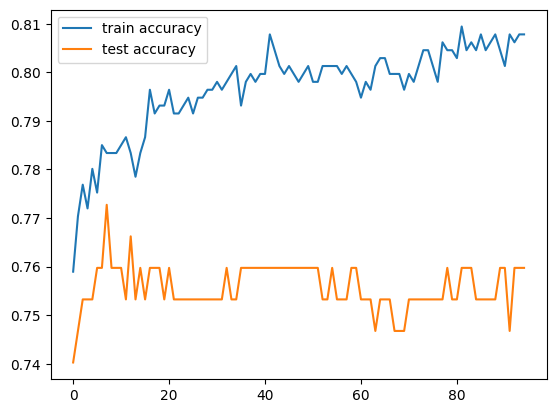

In [50]:
plt.plot(history.history['accuracy'],label='train accuracy')
plt.plot(history.history['val_accuracy'],label='test accuracy')
plt.legend()
plt.show()

```markdown
## Phase 2: Tuning the Number of Neurons (#neurons)

We run a search over a range of units in the hidden layer to determine the best width for classification performance.
```

In [57]:
def build_model(hp):
    model_neu = Sequential([
        keras.Input(shape=(8,))
    ])
    units = hp.Int('units', min_value=8, max_value=128, step=8)
    model_neu.add(Dense(units=units, activation='relu'))
    model_neu.add(Dense(1, activation='sigmoid'))

    model_neu.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model_neu

In [61]:
tuner_neu = kt.RandomSearch(build_model, objective='val_accuracy',max_trials=5,directory='mydir', project_name='neurons')

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [62]:
tuner_neu.search(X_train,y_train,epochs=5,validation_data=(X_test,y_test))

Trial 5 Complete [00h 00m 03s]
val_accuracy: 0.7662337422370911

Best val_accuracy So Far: 0.7662337422370911
Total elapsed time: 00h 00m 14s


In [63]:
tuner_neu.get_best_hyperparameters()[0].values

{'units': 96}

In [64]:
best_model_neu = tuner_neu.get_best_models(num_models=1)[0]

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [65]:
history_neu = best_model_neu.fit(X_train,y_train,batch_size=32,epochs=100,initial_epoch=5,validation_data=(X_test,y_test))

Epoch 6/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.7655 - loss: 0.4783 - val_accuracy: 0.7662 - val_loss: 0.5195
Epoch 7/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7720 - loss: 0.4649 - val_accuracy: 0.7597 - val_loss: 0.5125
Epoch 8/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7769 - loss: 0.4571 - val_accuracy: 0.7597 - val_loss: 0.5097
Epoch 9/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7818 - loss: 0.4512 - val_accuracy: 0.7532 - val_loss: 0.5101
Epoch 10/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7785 - loss: 0.4477 - val_accuracy: 0.7468 - val_loss: 0.5157
Epoch 11/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7785 - loss: 0.4451 - val_accuracy: 0.7468 - val_loss: 0.5163
Epoch 12/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7850 - loss: 0.4428 - val_accuracy: 0.7468 - val_loss: 0.5170
Epoch 13/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7834 - loss: 0.4396 - val_accuracy: 0.740

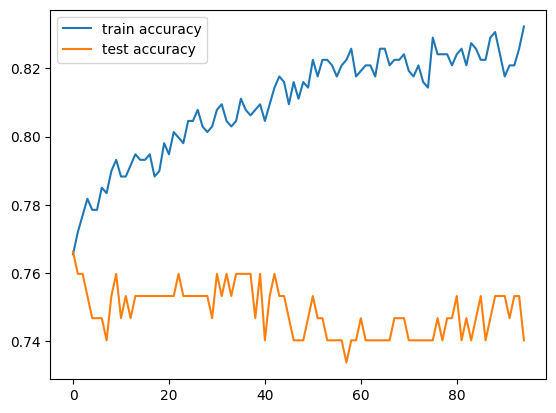

In [67]:
plt.plot(history_neu.history['accuracy'],label='train accuracy')
plt.plot(history_neu.history['val_accuracy'],label='test accuracy')
plt.legend()
plt.show()

```markdown
## Phase 3: Tuning the Number of Layers (#layers)

We run a search to determine the optimal depth by dynamically varying the number of layers in our model.
```

In [68]:
def build_model(hp):
    model_lay = Sequential([
        keras.Input(shape=(8,))
    ])

    # Add a variable number of layers dynamically
    for i in range(hp.Int('num_layers', min_value=1, max_value=10)):
        model_lay.add(Dense(72, activation='relu'))

    model_lay.add(Dense(1, activation='sigmoid'))
    model_lay.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model_lay

In [69]:
tuner_lay = kt.RandomSearch(build_model, objective='val_accuracy',max_trials=5,directory='mydir', project_name='layers')

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [70]:
tuner_lay.search(X_train,y_train,epochs=5,validation_data=(X_test,y_test))

Trial 5 Complete [00h 00m 05s]
val_accuracy: 0.7857142686843872

Best val_accuracy So Far: 0.7857142686843872
Total elapsed time: 00h 00m 20s


In [71]:
tuner_lay.get_best_hyperparameters()[0].values

{'num_layers': 2}

In [72]:
best_lay_model = tuner_lay.get_best_models(num_models=1)[0]

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 18 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [73]:
best_lay_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 72)             │           648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 72)             │         5,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 72)             │         5,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            73 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,233 (43.88 KB)

 Trainable params: 11,233 (43.88 KB)

 Non-trainable params: 0 (0.00 B)

In [74]:
history_lay = best_lay_model.fit(X_train,y_train,batch_size=32,epochs=100,initial_epoch=5,validation_data=(X_test,y_test))

Epoch 6/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.7980 - loss: 0.4466 - val_accuracy: 0.7662 - val_loss: 0.5040
Epoch 7/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7980 - loss: 0.4297 - val_accuracy: 0.7532 - val_loss: 0.5086
Epoch 8/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7948 - loss: 0.4220 - val_accuracy: 0.7597 - val_loss: 0.5170
Epoch 9/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8094 - loss: 0.4132 - val_accuracy: 0.7597 - val_loss: 0.5293
Epoch 10/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8029 - loss: 0.4072 - val_accuracy: 0.7532 - val_loss: 0.5313
Epoch 11/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8192 - loss: 0.4014 - val_accuracy: 0.7532 - val_loss: 0.5390
Epoch 12/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8111 - loss: 0.3976 - val_accuracy: 0.7403 - val_loss: 0.5396
Epoch 13/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8192 - loss: 0.3941 - val_accuracy: 0.746

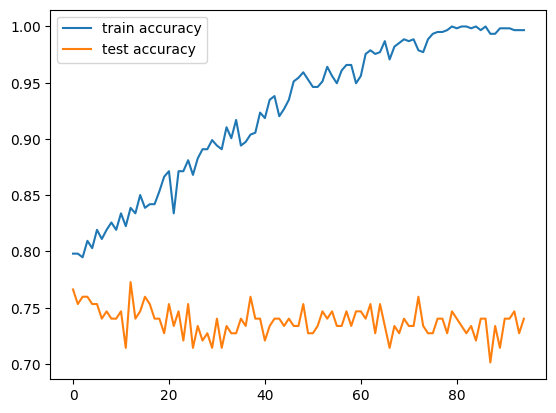

In [75]:
plt.plot(history_lay.history['accuracy'],label='train accuracy')
plt.plot(history_lay.history['val_accuracy'],label='test accuracy')
plt.legend()
plt.show()

```markdown
## Phase 4: Complete Joint Tuning with Dropout

We perform a complete search optimizing the number of layers, units per layer, activation functions, and optimizer choice together, while introducing Dropout layers to mitigate overfitting.
```

In [97]:
def build_model(hp):
    model = Sequential([
        keras.Input(shape=(8,))
    ])

    # Jointly tune the number of hidden layers, their units, and their activation functions
    for i in range(hp.Int('num_layers', min_value=1, max_value=10)):
        model.add(
            Dense(
                units=hp.Int(f'units{i}', min_value=8, max_value=128, step=8),
                activation=hp.Choice(f'activation{i}', values=['relu', 'tanh', 'sigmoid'])
            )
        )
        # Inject Dropout layers to avoid overfitting
        model.add(Dropout(hp.Choice(f'dropout{i}', values=[0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9])))

    model.add(Dense(1, activation='sigmoid'))
    model.compile(
        optimizer=hp.Choice('optimizer', values=['adam', 'SGD', 'rmsprop', 'adadelta']),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

In [98]:
tuner = kt.RandomSearch(build_model, objective='val_accuracy',max_trials=5,directory='mydir', project_name='complete1')

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [99]:
tuner.search(X_train,y_train,epochs=5,validation_data=(X_test,y_test))

Trial 5 Complete [00h 00m 05s]
val_accuracy: 0.6428571343421936

Best val_accuracy So Far: 0.6948052048683167
Total elapsed time: 00h 00m 20s


In [100]:
tuner.get_best_hyperparameters()[0].values

{'num_layers': 4,
 'units0': 32,
 'activation0': 'relu',
 'dropout0': 0.4,
 'optimizer': 'adam',
 'units1': 8,
 'activation1': 'relu',
 'dropout1': 0.1,
 'units2': 8,
 'activation2': 'relu',
 'dropout2': 0.1,
 'units3': 8,
 'activation3': 'relu',
 'dropout3': 0.1}

In [101]:
model = tuner.get_best_models(num_models=1)[0]

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 22 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [102]:
history = model.fit(X_train,y_train,epochs=200,initial_epoch=5,validation_data=(X_test,y_test))

Epoch 6/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.6433 - loss: 0.6816 - val_accuracy: 0.6494 - val_loss: 0.6734
Epoch 7/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7020 - loss: 0.6678 - val_accuracy: 0.6688 - val_loss: 0.6632
Epoch 8/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6775 - loss: 0.6594 - val_accuracy: 0.6623 - val_loss: 0.6458
Epoch 9/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6808 - loss: 0.6439 - val_accuracy: 0.6688 - val_loss: 0.6263
Epoch 10/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6726 - loss: 0.6311 - val_accuracy: 0.6688 - val_loss: 0.6056
Epoch 11/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6938 - loss: 0.6111 - val_accuracy: 0.6883 - val_loss: 0.5831
Epoch 12/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6987 - loss: 0.5885 - val_accuracy: 0.7078 - val_loss: 0.5634
Epoch 13/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7182 - loss: 0.5724 - val_accuracy: 0.727

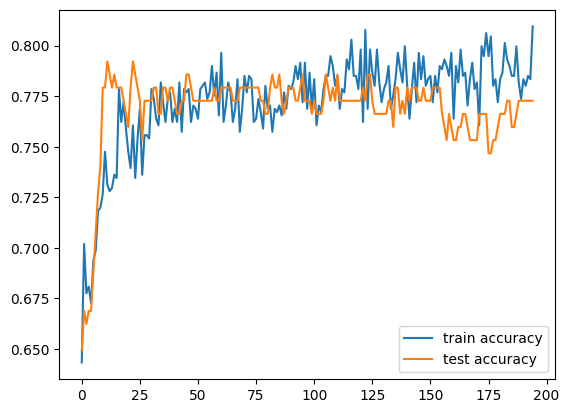

In [103]:
plt.plot(history.history['accuracy'],label='train accuracy')
plt.plot(history.history['val_accuracy'],label='test accuracy')
plt.legend()
plt.show()

### Summary and Conclusions
By implementing Keras Tuner with a flexible model search space (varying layers, nodes, activation functions, and optimizer) along with **Dropout layers**, we successfully counteracted overfitting and established an optimized deep learning model for diabetes classification.